In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('train.csv')
df = df.drop(['id','CustomerId'], axis=1)
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,Chia,593.0,France,Male,46.0,9.0,0.00,2.0,1.0,1.0,83629.60,0.0
1,Yeh,539.0,France,Female,33.0,3.0,0.00,2.0,0.0,1.0,73979.86,0.0
2,Ch'ien,709.0,Spain,Male,21.0,2.0,0.00,2.0,0.0,1.0,25669.10,0.0
3,Palerma,628.0,Germany,Female,33.0,4.0,109342.82,1.0,1.0,1.0,67611.36,0.0
4,Palerma,640.0,France,Male,34.0,9.0,127545.99,1.0,1.0,1.0,147545.65,0.0


In [ ]:
print(df['Exited'].value_counts())

Exited
0.0    11896
1.0     3104
Name: count, dtype: int64


In [ ]:
print(f"Number of duplicate rows: {df.duplicated().sum()}")
print("\nNull values per column:")
print(df.isnull().sum())

Number of duplicate rows: 0

Null values per column:
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [ ]:
df.shape

(15000, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Surname          15000 non-null  object 
 1   CreditScore      15000 non-null  float64
 2   Geography        15000 non-null  object 
 3   Gender           15000 non-null  object 
 4   Age              15000 non-null  float64
 5   Tenure           15000 non-null  float64
 6   Balance          15000 non-null  float64
 7   NumOfProducts    15000 non-null  float64
 8   HasCrCard        15000 non-null  float64
 9   IsActiveMember   15000 non-null  float64
 10  EstimatedSalary  15000 non-null  float64
 11  Exited           15000 non-null  float64
dtypes: float64(9), object(3)
memory usage: 1.4+ MB


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Columns to be label encoded
columns_to_encode_label = ['Surname', 'Geography', 'Gender']

# Apply Label Encoding to the specified columns in df
for column in columns_to_encode_label:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])

print("DataFrame head after label encoding:")
print(df.head())

print("\nDataFrame info after label encoding:")
df.info()

print("\nNote: The 'X', 'y', 'X_train', 'X_test' variables, and trained models do not reflect these changes yet.")
print("If you wish to use these newly encoded features, you will need to re-run the cells for data splitting, model training, and evaluation.")

DataFrame head after label encoding:
   Surname  CreditScore  Geography  Gender   Age  Tenure    Balance  \
0       74        593.0          0       1  46.0     9.0       0.00   
1      722        539.0          0       0  33.0     3.0       0.00   
2       71        709.0          2       1  21.0     2.0       0.00   
3      576        628.0          1       0  33.0     4.0  109342.82   
4      576        640.0          0       1  34.0     9.0  127545.99   

   NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  
0            2.0        1.0             1.0         83629.60     0.0  
1            2.0        0.0             1.0         73979.86     0.0  
2            2.0        0.0             1.0         25669.10     0.0  
3            1.0        1.0             1.0         67611.36     0.0  
4            1.0        1.0             1.0        147545.65     0.0  

DataFrame info after label encoding:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# At this point, df has label encoded categorical features.
# Feature scaling will be applied to X_train and X_test later with the specific scaler.

print("DataFrame 'df' is ready for splitting into features and target, and subsequent feature selection and scaling.")
print("\nDataFrame head after label encoding (before feature selection/scaling for modeling):")
print(df.head())

print("\nDataFrame info after label encoding (before feature selection/scaling for modeling):")
df.info()

DataFrame 'df' is ready for splitting into features and target, and subsequent feature selection and scaling.

DataFrame head after label encoding (before feature selection/scaling for modeling):
   Surname  CreditScore  Geography  Gender   Age  Tenure    Balance  \
0       74        593.0          0       1  46.0     9.0       0.00   
1      722        539.0          0       0  33.0     3.0       0.00   
2       71        709.0          2       1  21.0     2.0       0.00   
3      576        628.0          1       0  33.0     4.0  109342.82   
4      576        640.0          0       1  34.0     9.0  127545.99   

   NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  
0            2.0        1.0             1.0         83629.60     0.0  
1            2.0        0.0             1.0         73979.86     0.0  
2            2.0        0.0             1.0         25669.10     0.0  
3            1.0        1.0             1.0         67611.36     0.0  
4            1.0      

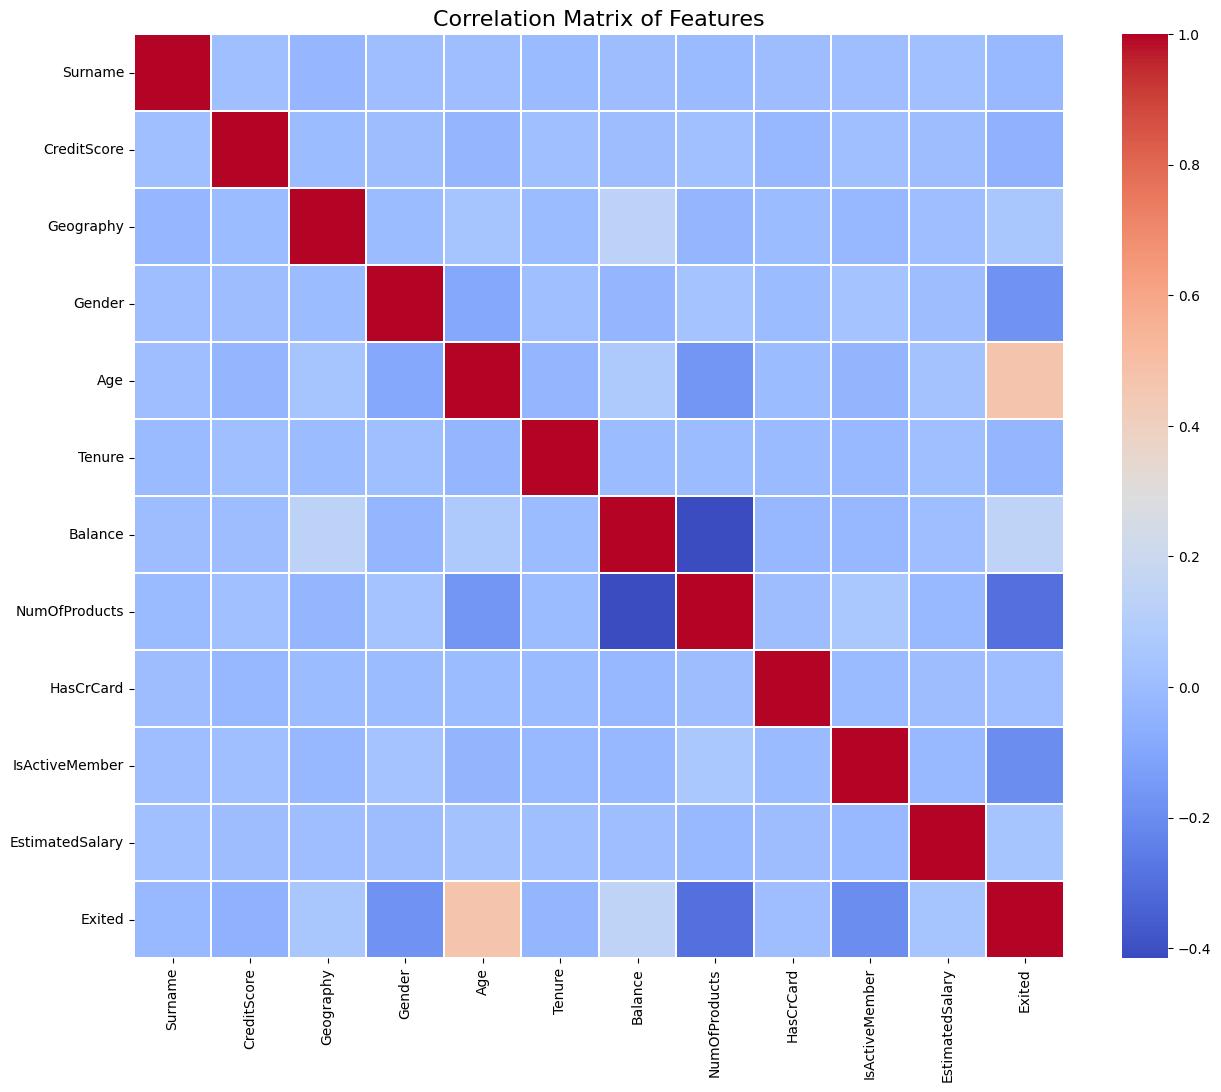

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix for the entire DataFrame
correlation_matrix = df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(15, 12))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(correlation_matrix, cmap='coolwarm', fmt=".2f", linewidths=.05)

plt.title('Correlation Matrix of Features', fontsize=16)
plt.show()

In [ ]:
df = df.drop(['HasCrCard','EstimatedSalary', 'Tenure', 'Surname', 'CreditScore'], axis=1)

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('Exited', axis=1)
y = df['Exited']

# Split the entire dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Now, split the training data into class zero and class one
X_train_zero = X_train[y_train == 0]
y_train_zero = y_train[y_train == 0]

X_train_one = X_train[y_train == 1]
y_train_one = y_train[y_train == 1]

print("Shapes after initial train-test split:")
print(f"  X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"  X_test: {X_test.shape}, y_test: {y_test.shape}")

print("\nShapes of training data split by class:")
print(f"  X_train_zero: {X_train_zero.shape}, y_train_zero: {y_train_zero.shape}")
print(f"  X_train_one: {X_train_one.shape}, y_train_one: {y_train_one.shape}")

Shapes after initial train-test split:
  X_train: (12000, 6), y_train: (12000,)
  X_test: (3000, 6), y_test: (3000,)

Shapes of training data split by class:
  X_train_zero: (9517, 6), y_train_zero: (9517,)
  X_train_one: (2483, 6), y_train_one: (2483,)


In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# Initialize and train the Isolation Forest model
# contamination is the proportion of outliers in the dataset
iforest = IsolationForest(random_state=42, contamination=0.1)
iforest.fit(X_train)

IsolationForest(contamination=0.1, random_state=42)

In [ ]:
from sklearn.metrics import classification_report

# Predict on the scaled X_test data
y_test_pred_ocsvm = iforest.predict(X_test)

# Map One-Class SVM predictions to match 0 (Not Exited) and 1 (Exited) labels
# -1 (anomaly) -> 1 (Exited)
#  1 (normal)   -> 0 (Not Exited)
y_test_pred_mapped = np.where(y_test_pred_ocsvm == -1, 1, 0)

# Generate and print the classification report
print("Classification Report for One-Class SVM on X_test:")
print(classification_report(y_test, y_test_pred_mapped, target_names=['Not Exited', 'Exited']))

Classification Report for One-Class SVM on X_test:
              precision    recall  f1-score   support

  Not Exited       0.81      0.92      0.86      2379
      Exited       0.39      0.19      0.26       621

    accuracy                           0.77      3000
   macro avg       0.60      0.56      0.56      3000
weighted avg       0.73      0.77      0.74      3000



In [ ]:
from sklearn.metrics import roc_auc_score

# Calculate the ROC AUC score
roc_auc = roc_auc_score(y_test, y_test_pred_mapped)

print(f"ROC AUC Score: {roc_auc:.4f}")

ROC AUC Score: 0.5571


In [ ]:
df_sub = pd.read_csv('sample_submission.csv')
df_sub.head()

,id,Exited
0,15000,0.5
1,15001,0.5
2,15002,0.5
3,15003,0.5
4,15004,0.5


In [ ]:
# Load the test dataset
test_df = pd.read_csv('test.csv')

# Store original 'id' for submission file
submission_ids = test_df['id']

# Drop 'id' and 'CustomerId' from test_df
test_df = test_df.drop(['id', 'CustomerId'], axis=1)

# --- Preprocessing for test_df (same as training data) ---

from sklearn.preprocessing import LabelEncoder

# Columns to be label encoded (as done for training data)
columns_to_encode_label = ['Surname', 'Geography', 'Gender']

# Apply Label Encoding to the specified columns in test_df
for column in columns_to_encode_label:
    le = LabelEncoder()
    test_df[column] = le.fit_transform(test_df[column])

# Now test_df has label encoded columns, prepare it for further processing
test_df_processed = test_df.copy()

# Drop columns that were dropped from the training DataFrame (df) to create X
# These columns were identified in the cell 'kVlhozDbl79o'
columns_to_drop_from_test = ['HasCrCard','EstimatedSalary', 'Tenure', 'Surname', 'CreditScore']
test_df_processed = test_df_processed.drop(columns=columns_to_drop_from_test, errors='ignore')

# Ensure the order of columns is the same as in X (training features)
# This is critical for the scaler and model to work correctly.
# X was created from df.drop('Exited', axis=1) after all preprocessing.

# Add missing columns (with 0) and drop extra columns if any after manual dropping
missing_cols = set(X.columns) - set(test_df_processed.columns)
for c in missing_cols:
    test_df_processed[c] = 0

extra_cols = set(test_df_processed.columns) - set(X.columns)
test_df_processed = test_df_processed.drop(columns=list(extra_cols), errors='ignore')

# Reorder columns to match X
test_df_processed = test_df_processed[X.columns]

# The numerical_cols for scaling should be the actual columns of X.
# X already contains only the features that were kept and scaled during training.
numerical_cols_for_scaling = X.columns.tolist()

# Apply scaler.transform() (from Fwlh5-egfBBU) to the numerical columns of test_df_processed
test_df_processed[numerical_cols_for_scaling] = scaler.transform(test_df_processed[numerical_cols_for_scaling])

# --- Prediction ---

# Predict on the preprocessed and scaled test data using the trained Isolation Forest model
# The iforest model was trained on X_train (which was already scaled by scaler)
# So, test_df_processed should also be scaled by scaler
predictions = iforest.predict(test_df_processed)

# Map Isolation Forest predictions (-1 for outliers, 1 for inliers) to 0 or 1
# -1 (anomaly) -> 1 (Exited)
#  1 (normal)   -> 0 (Not Exited)
final_predictions = np.where(predictions == -1, 1, 0)

# --- Create submission file ---
submission_df = pd.DataFrame({'id': submission_ids, 'Exited': final_predictions})

# Display the head of the submission file
print("Submission file head:")
print(submission_df.head())

# Save the submission file to CSV
submission_df.to_csv('submission.csv', index=False)
print("\nSubmission file 'submission.csv' created successfully.")

Submission file head:
      id  Exited
0  15000       1
1  15001       1
2  15002       1
3  15003       1
4  15004       1

Submission file 'submission.csv' created successfully.
